# Denoising
In this notebook we use multi-scale roto-translational total variation (MS-RT-TV) flow to denoise images corrupted by correlated white noise, as in Section 5 of ["Multi-Scale Roto-Translational Total Variation Flow"]().
We compare to roto-translational total variation (RT-TV) flow, soft-thresholding of wavelet coefficients, and BM3D

This notebook exports for each method the peak signal-to-noise ratios (PSNRs) as a function of the scale parameter, normalised to the optimal scale parameter.
This data is used to create Fig. 3.

The notebook also exports the images at the optimal PSNR for each method, which are shown in Fig. 2.

In [5]:
import torch
import numpy as np
from msrtv import SE2, SIM2
from msrtv.utils import PSNR, gaussian_blur_2d_separable
from bm3d import bm3d
from tqdm.auto import tqdm
from PIL import Image
from pathlib import Path
import json
import matplotlib.pyplot as plt
with open("plot.json", "r") as f:
    plot_config = json.load(f)
latex_line_width = plot_config.pop("latex_line_width")
notebook_width = plot_config.pop("notebook_width")
plt.rcParams.update(plot_config)

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(4);
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [6]:
print(device)

cuda


In [7]:
# colours
red = "#B6321C" # BrickRed
blue = "#0071BC" # RoyalBlue
green = "#009B55" # ForestGreen
purple = "#613F99" # RoyalPurple

def plot_image(ax, image, **kwargs):
    image = image.cpu()
    return ax.imshow(image, **kwargs)

output_directory = Path("output")
data_directory = Path("data")
config_path = Path("config.json")

In [8]:
test_case = "remco" # "collagen", "monalisa", "retina"

with open(config_path, encoding="utf-8") as f:
    config_all = json.load(f)
config_test = config_all[test_case]
# Default parameters, overridden by those of the test case; method parameters are merged per method.
config = config_all["defaults"] | config_test
config |= {key: value | config_test.get(key, {}) for key, value in config_all["defaults"].items() if isinstance(value, dict)}

def load_image(path):
    """Load image at `path` as a float32 tensor."""
    return torch.as_tensor(np.array(Image.open(path).convert("L")), dtype=torch.float32, device=device)

ground_truth = load_image(data_directory / config["ground_truth"])
σ_noise = config["sigma_noise"]
ρ_noise = config["rho_noise"]
noise = σ_noise * torch.randn(*ground_truth.shape, device=device)
noise = gaussian_blur_2d_separable(noise, (ρ_noise, ρ_noise))
noisy = (ground_truth + noise).clamp(0., 255.)


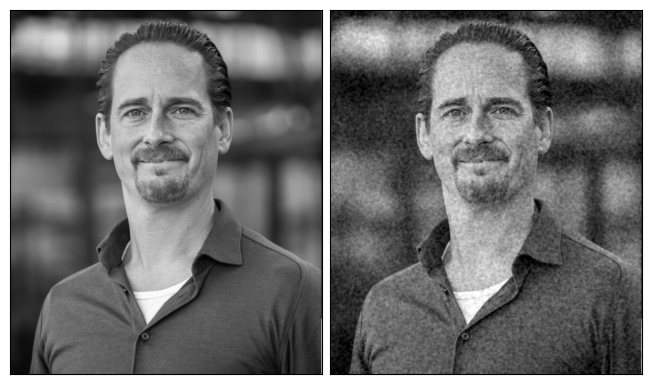

In [9]:
fig, ax = plt.subplots(1, 2)
plot_image(ax[0], ground_truth.cpu())
plot_image(ax[1], noisy.cpu());

In [10]:
S, Or = 4, 32
H, W = ground_truth.shape
N_spatial = max(H, W)
aspect = H / W

config_SE2 = config["SE2"]
ξ_SE2 = config_SE2["xi"]
σ_s_SE2 = config_SE2["σ_s"]
σ_o_SE2 = config_SE2["σ_o"]
T_SE2 = config_SE2["T"]

config_SIM2 = config["SIM2"]
ξ_SIM2 = config_SIM2["xi"]
φ = config_SIM2["phi"]
a = config_SIM2["a"]
σ_s_SIM2 = config_SIM2["σ_s"]
σ_o_SIM2 = config_SIM2["σ_o"]
σ_a = config_SIM2["σ_a"]
cut_freq = config_SIM2["cut_freq"]
T_SIM2 = config_SIM2["T"]

G_inv_SIM2 = (ξ_SIM2**-2, ξ_SIM2**-2, 1., φ**-2)
G_inv_SE2 = (ξ_SE2**-2, ξ_SE2**-2, 1.)

quantiles_threshold = torch.linspace(0, 1, 50, device=device)

scales_bm3d = torch.arange(0., config["bm3d_max_scale"], config["bm3d_step_scale"])

In [11]:
cakewavelets = SE2.cakewavelettransform.cakewavelet_stack_fourier(N_spatial, Or, inflection_point=None)
U_SE2 = SE2.cakewavelettransform.wavelet_transform(noisy, cakewavelets)
simoncelli_filters, lowpass = SIM2.simoncellitransform.steerable_wavelet_stack(H, W, S, Or, cut_freq=cut_freq, dilation=a)
U_SIM2, U_low = SIM2.simoncellitransform.wavelet_transform(noisy, simoncelli_filters, lowpass)

In [12]:
ground_truth_SIM2 = SIM2.tvflow.GroundTruth(
    ground_truth=ground_truth,
    u_low=U_low,
    filters=simoncelli_filters,
    lowpass=lowpass,
)

In [13]:
def denoise_bm3d(u, scales, ground_truth=None, max_val=255.):
    """
    Denoise with BM3D, as described by Dabov et al.[1] For each noise scale
    `σ`, denoise `u` with BM3D assuming noise standard deviation `σ`.

    Args:
        `u`: torch.Tensor noisy image on the CPU, with shape [H, W].
        `scales`: iterable of assumed noise standard deviations.
        `ground_truth`: torch.Tensor ground truth on the CPU, with shape
          [H, W], for computing PSNR.
        `max_val`: maximum value images take, for computing PSNR.

    Returns:
        numpy.ndarray denoised image for the last scale, and list of PSNRs for
        each scale.

    References:
        [1]: K. Dabov, A. Foi, V. Katkovnik, and K. Egiazarian.
          "Image Denoising by Sparse 3-D Transform-Domain Collaborative
          Filtering." In: IEEE Transactions on Image Processing 16 (2007),
          pp. 2080--2095.
          DOI:10.1109/TIP.2007.901238.
    """
    PSNRs = []
    for σ in tqdm(scales):
        denoised = bm3d(u, σ)
        if ground_truth is not None:
            PSNRs.append(PSNR(torch.as_tensor(denoised), ground_truth, max_val=max_val))
    return denoised, PSNRs

In [14]:
_, PSNRs_SE2 = SE2.tvflow.denoise(U_SE2, T_SE2, G_inv_SE2, σ_s_SE2, σ_o_SE2, ground_truth=ground_truth)
_, PSNRs_SIM2 = SIM2.tvflow.denoise(U_SIM2, T_SIM2, G_inv_SIM2, a, σ_s_SIM2, σ_o_SIM2, σ_a, ground_truth=ground_truth_SIM2)
_, PSNRs_threshold = SIM2.threshold.denoise(U_SIM2, quantiles_threshold, ground_truth=ground_truth_SIM2)
_, PSNRs_bm3d = denoise_bm3d(noisy.cpu(), scales_bm3d, ground_truth=ground_truth.cpu())

100%|██████████| 100/100 [07:31<00:00,  4.52s/it]


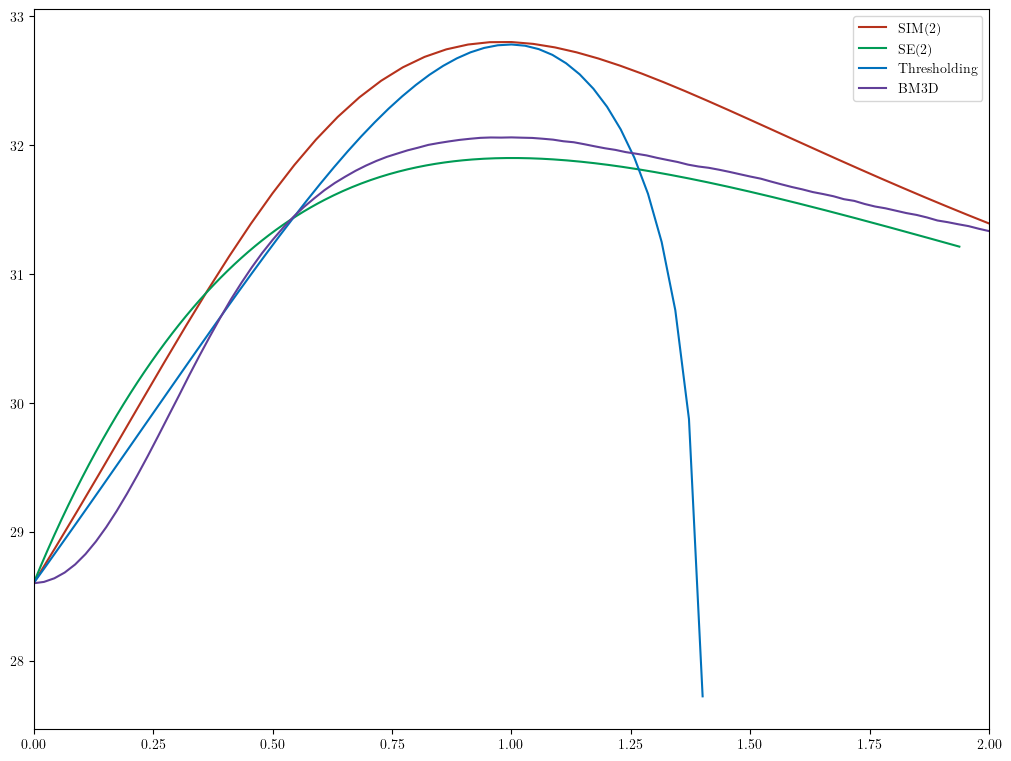

In [15]:
i_opt_SE2 = torch.tensor(PSNRs_SE2).argmax()
Ts_SE2 = torch.linspace(0, T_SE2, len(PSNRs_SE2))
T_SE2_opt = Ts_SE2[i_opt_SE2]
Ts_SE2_normalised = Ts_SE2 / T_SE2_opt
i_opt_SIM2 = torch.tensor(PSNRs_SIM2).argmax()
Ts_SIM2 = torch.linspace(0, T_SIM2, len(PSNRs_SIM2))
T_SIM2_opt = Ts_SIM2[i_opt_SIM2]
Ts_SIM2_normalised = Ts_SIM2 / T_SIM2_opt
i_opt_threshold = torch.tensor(PSNRs_threshold).argmax()
quantile_threshold_opt = quantiles_threshold.cpu()[i_opt_threshold]
quantiles_threshold_normalised = quantiles_threshold.cpu() / quantile_threshold_opt
i_opt_bm3d = torch.tensor(PSNRs_bm3d).argmax()
scale_bm3d_opt = scales_bm3d[i_opt_bm3d]
scales_bm3d_normalised = scales_bm3d / scale_bm3d_opt


fig, ax = plt.subplots(1, 1, figsize=(notebook_width, 0.75 * notebook_width))
ax.plot(Ts_SIM2_normalised, PSNRs_SIM2, label="SIM(2)", color=red)
ax.plot(Ts_SE2_normalised, PSNRs_SE2, label="SE(2)", color=green)
ax.plot(quantiles_threshold_normalised, PSNRs_threshold, label="Thresholding", color=blue)
ax.plot(scales_bm3d_normalised, PSNRs_bm3d, label="BM3D", color=purple)
ax.set_xlim(0, 2)
# ax.set_ylim(24.5, 27.5)
ax.tick_params(bottom=True, left=True, labelbottom=True, labelleft=True)
ax.legend();

In [16]:
output_directory.mkdir(exist_ok=True)
Ts_SE2 = torch.linspace(0, T_SE2, len(PSNRs_SE2))
Ts_SIM2 = torch.linspace(0, T_SIM2, len(PSNRs_SIM2))
np.savetxt(output_directory / f"{test_case}_TV_SE2.dat", np.stack((Ts_SE2_normalised, PSNRs_SE2), axis=-1))
np.savetxt(output_directory / f"{test_case}_TV_SIM2.dat", np.stack((Ts_SIM2_normalised, PSNRs_SIM2), axis=-1))
np.savetxt(output_directory / f"{test_case}_threshold.dat", np.stack((quantiles_threshold_normalised.cpu(), PSNRs_threshold), axis=-1))
np.savetxt(output_directory / f"{test_case}_BM3D.dat", np.stack((scales_bm3d_normalised, PSNRs_bm3d), axis=-1))

In [17]:
U_denoised_SE2, _ = SE2.tvflow.denoise(U_SE2, Ts_SE2[i_opt_SE2], G_inv_SE2, σ_s_SE2, σ_o_SE2)
U_denoised_SIM2, _ = SIM2.tvflow.denoise(U_SIM2, Ts_SIM2[i_opt_SIM2], G_inv_SIM2, a, σ_s_SIM2, σ_o_SIM2, σ_a)
U_denoised_threshold, _ = SIM2.threshold.denoise(U_SIM2, [quantiles_threshold[i_opt_threshold]])
denoised_bm3d, _ = denoise_bm3d(noisy.cpu(), [scales_bm3d[i_opt_bm3d]])

100%|██████████| 1/1 [00:04<00:00,  4.21s/it]


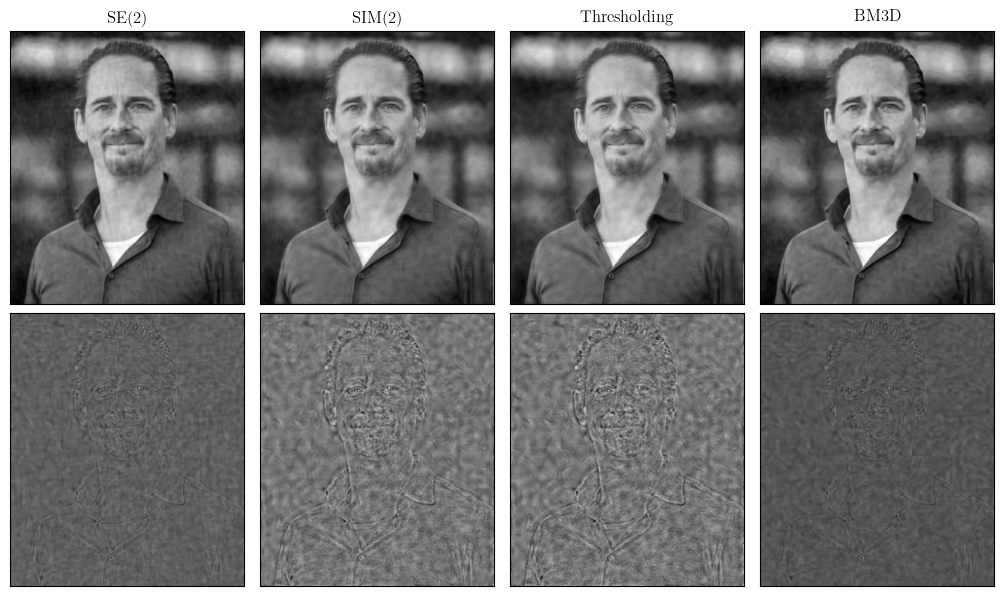

In [18]:
denoised_SE2 = U_denoised_SE2.sum(-3)
denoised_SIM2 = SIM2.simoncellitransform.inverse_wavelet_transform(U_denoised_SIM2, U_low, simoncelli_filters, lowpass)
denoised_threshold = SIM2.simoncellitransform.inverse_wavelet_transform(U_denoised_threshold, U_low, simoncelli_filters, lowpass)
denoised_bm3d = torch.as_tensor(denoised_bm3d, device=device)

fig, ax = plt.subplots(2, 4, figsize=(notebook_width, (2 * aspect / 4) * notebook_width))
plot_image(ax[0, 0], denoised_SE2)
ax[0, 0].set_title("SE(2)")
plot_image(ax[0, 1], denoised_SIM2)
ax[0, 1].set_title("SIM(2)")
plot_image(ax[0, 2], denoised_threshold)
ax[0, 2].set_title("Thresholding")
plot_image(ax[0, 3], denoised_bm3d)
ax[0, 3].set_title("BM3D")
plot_image(ax[1, 0], ground_truth - denoised_SE2)
plot_image(ax[1, 1], ground_truth - denoised_SIM2)
plot_image(ax[1, 2], ground_truth - denoised_threshold)
plot_image(ax[1, 3], ground_truth - denoised_bm3d);

In [19]:
def save_image(path, image, invert=False):
    """Save float image `image` with values in [0, 255] as an 8-bit PNG at `path`."""
    image = image.clamp(0., 255.).round().to(torch.uint8).cpu().numpy()
    if invert:
        image = 255 - image
    Image.fromarray(image).save(path)

name = test_case
save_image(output_directory / f"{name}_clean.png", ground_truth, invert=test_case == "collagen")
save_image(output_directory / f"{name}_noisy.png", noisy, invert=test_case == "collagen")
save_image(output_directory / f"{name}_SE2.png", denoised_SE2, invert=test_case == "collagen")
save_image(output_directory / f"{name}_SIM2.png", denoised_SIM2, invert=test_case == "collagen")
save_image(output_directory / f"{name}_threshold.png", denoised_threshold, invert=test_case == "collagen")
save_image(output_directory / f"{name}_BM3D.png", denoised_bm3d, invert=test_case == "collagen")


In [20]:
max(PSNRs_SIM2), max(PSNRs_SE2), max(PSNRs_threshold), max(PSNRs_bm3d)

(32.80117583697696, 31.90163387393277, 32.7822620548218, 32.061558187807215)